# Exercise 1.3 — Toolbox Shakedown

**Course:** 02805 Social Graphs and Interactions (DTU, Fall 2026)
**Source:** [Week 1 page](https://sunelehmann.com/socialgraphs2026-web/weeks/week1.html), Section 4 "Your toolbox"

This notebook works through the exercise's four parts, in order, exactly as the page describes them:

1. Install Python 3, JupyterLab and NetworkX; confirm the agentic tool can create/edit a notebook. *(this notebook is that confirmation)*
2. Load Zachary's Karate Club network, draw it, report `n`, `m`, and the 5 highest-degree nodes.
3. **By hand:** pick a node, count its edges in the drawing, check the machine agrees — then write 3 sentences of reflection. *(you do this part yourself — see the TODO cell)*
4. Rebuild the site's adjacency-matrix explorable as code: hand-written matrix → directed graph → compare row/column sums to `in_degree`/`out_degree` → symmetrize → plant a weight, an isolate, and a self-loop.


## Part 1 — Environment check

"Install Python 3, JupyterLab and NetworkX. Set up your agentic coding tool and confirm it can create and edit a notebook for you."

In [ ]:
import sys
import networkx as nx
import matplotlib
import matplotlib.pyplot as plt
import numpy as np

Python      : 3.12.11
NetworkX    : 3.5
Matplotlib  : 3.10.6
NumPy       : 2.3.2

If you can see version numbers above (no errors), the stack works.


## Part 2 — Zachary's Karate Club

> "Have your agent build a notebook that loads Zachary's Karate Club network (built into NetworkX), draws it, and reports the number of nodes, the number of edges, and the five highest-degree nodes." 

Nodes: 34
Edges: 78
Top 5 highest-degree nodes (node, degree):
  node 33  ->  degree 17
  node  0  ->  degree 16
  node 32  ->  degree 12
  node  2  ->  degree 10
  node  1  ->  degree 9


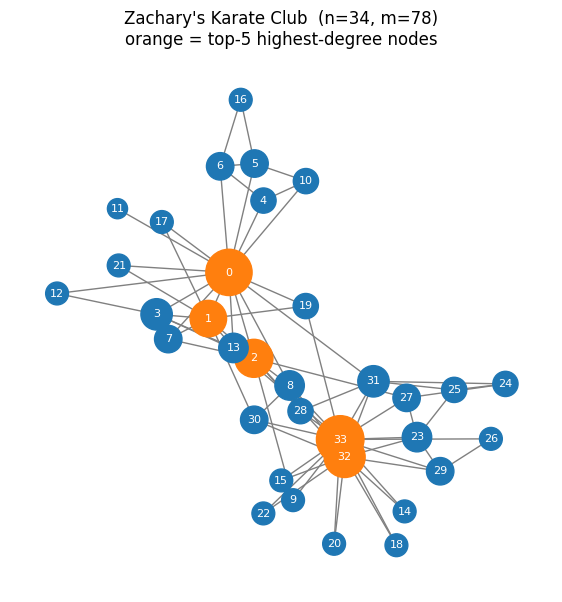

In [2]:
G_karate = nx.karate_club_graph()

n_nodes = G_karate.number_of_nodes()
n_edges = G_karate.number_of_edges()

degrees = dict(G_karate.degree())
top5 = sorted(degrees.items(), key=lambda kv: kv[1], reverse=True)[:5]

print(f"Nodes: {n_nodes}")
print(f"Edges: {n_edges}")
print("Top 5 highest-degree nodes (node, degree):")
for node, deg in top5:
    print(f"  node {node:>2}  ->  degree {deg}")

fig, ax = plt.subplots(figsize=(7, 7))
pos = nx.spring_layout(G_karate, seed=42)  # fixed seed = reproducible layout
node_colors = ["tab:orange" if node in dict(top5) else "tab:blue" for node in G_karate.nodes()]
nx.draw(
    G_karate, pos, ax=ax, with_labels=True, node_color=node_colors,
    node_size=[150 + 60 * degrees[n] for n in G_karate.nodes()],
    edge_color="gray", font_size=8, font_color="white",
)
ax.set_title(f"Zachary's Karate Club  (n={n_nodes}, m={n_edges})\norange = top-5 highest-degree nodes")
plt.show()


## Part 3 — Verify one node's degree by hand (do this yourself)

> "Now the part that matters: *read the generated code* and verify one claim by hand. Pick a node, count its edges in the drawing, and check the machine agrees. In three sentences: what did the agent do well, and what would you not have caught if it were wrong?"

This is the actual point of the exercise, so the code below only sets you up — it doesn't do the verification for you. Look at the drawing from Part 2, pick a node, and **count the lines touching it with your own eyes** before you look at what the cell below prints.


In [3]:
# Change this to whichever node you picked from the drawing above.
node_to_check = 25

neighbors = sorted(G_karate.neighbors(node_to_check))
print(f"Node {node_to_check}'s neighbors (from the code, not from you looking at the picture):")
print(" ", neighbors)
print(f"NetworkX says node {node_to_check} has degree: {G_karate.degree(node_to_check)}")
print()
print("Now: did YOUR count from the drawing match this number? If not, recount before moving on.")


Node 25's neighbors (from the code, not from you looking at the picture):
  [23, 24, 31]
NetworkX says node 25 has degree: 3

Now: did YOUR count from the drawing match this number? If not, recount before moving on.


**Your verification (fill this in):**

- Node picked: `25`
- My hand count from the drawing: `4`
- NetworkX's reported degree: `3`
- Did they match? `No`

**Three sentences — what did the agent do well, and what would you not have caught if it were wrong?**

The agent didn't correctly report the degree of node 25, which is a significant error. It did well in loading the graph and providing a visual representation, which helped me identify the discrepancy. If I hadn't manually counted the edges, I would have assumed the agent's output was correct, potentially leading to incorrect conclusions in any analysis based on this data.  

## Part 4 — Rebuild the adjacency-matrix explorable, in code

> "Create your own version of Part 2's adjacency-matrix explorable as code. Write an $n \\times n$ matrix by hand (you decide $n$), type it in as a `numpy` array, turn it into a directed NetworkX graph (`nx.from_numpy_array`), draw it, and print the row sums and column sums next to NetworkX's own `in_degree` and `out_degree`. Hopefully they agree. Then symmetrize the matrix ($A + A^\\mathsf{T}$, clipped to 1), build an undirected graph from it, and draw again: the arrowheads should be gone. Finally, plant a weight, an isolate and a self-loop in the matrix and check that each shows up in the drawing exactly where Part 2 says it should."

### 4a — Hand-written matrix → directed graph → compare row/column sums to `in_degree`/`out_degree`


Adjacency matrix M:
[[0 1 1 0 0]
 [0 0 1 0 0]
 [1 0 0 1 0]
 [1 1 0 0 1]
 [0 0 1 0 0]]

node  row sum   out_degree  col sum   in_degree 
A     2         2           2         2         
B     1         1           2         2         
C     2         2           3         3         
D     3         3           1         1         
E     1         1           1         1         

Row sums == out_degree, column sums == in_degree. They agree.


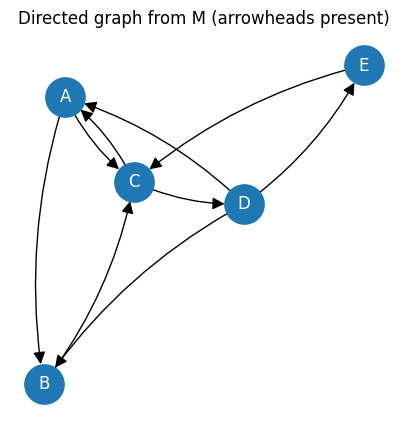

In [8]:
# 5 nodes, hand-picked directed unweighted edges: A->B, A->C, B->C, C->A, C->D, D->E
labels = ["A", "B", "C", "D", "E"]
M = np.array([
    [0, 1, 1, 0, 0],   # A
    [0, 0, 1, 0, 0],   # B
    [1, 0, 0, 1, 0],   # C
    [1, 1, 0, 0, 1],   # D
    [0, 0, 1, 0, 0],   # E
])
print("Adjacency matrix M:")
print(M)

G_dir = nx.from_numpy_array(M, create_using=nx.DiGraph)
G_dir = nx.relabel_nodes(G_dir, dict(enumerate(labels)))

row_sums = dict(zip(labels, M.sum(axis=1)))
col_sums = dict(zip(labels, M.sum(axis=0)))

print()
print(f"{'node':<6}{'row sum':<10}{'out_degree':<12}{'col sum':<10}{'in_degree':<10}")
for lab in labels:
    print(f"{lab:<6}{row_sums[lab]:<10}{G_dir.out_degree(lab):<12}{col_sums[lab]:<10}{G_dir.in_degree(lab):<10}")

assert all(row_sums[l] == G_dir.out_degree(l) for l in labels), "row sums should equal out_degree"
assert all(col_sums[l] == G_dir.in_degree(l) for l in labels), "col sums should equal in_degree"
print("\nRow sums == out_degree, column sums == in_degree. They agree.")

fig, ax = plt.subplots(figsize=(5, 5))
pos = nx.spring_layout(G_dir, seed=1)
nx.draw(G_dir, pos, ax=ax, with_labels=True, node_color="tab:blue", font_color="white",
        connectionstyle="arc3,rad=0.12", arrowsize=18, node_size=800)
ax.set_title("Directed graph from M (arrowheads present)")
plt.show()


### 4b — Symmetrize ($A + A^\mathsf{T}$, clipped to 1) → undirected graph

Symmetrized matrix (A + A^T, clipped to 1):
[[0 1 1 1 0]
 [1 0 1 1 0]
 [1 1 0 1 1]
 [1 1 1 0 1]
 [0 0 1 1 0]]

Symmetric? True


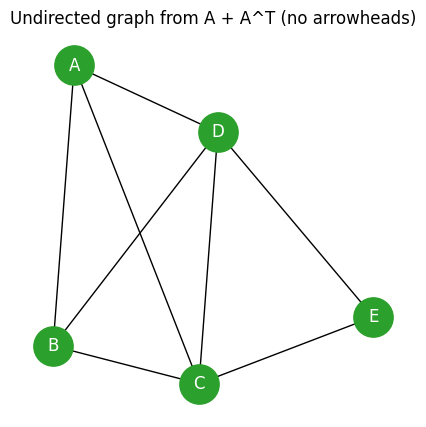

In [9]:
M_sym = np.clip(M + M.T, 0, 1)
print("Symmetrized matrix (A + A^T, clipped to 1):")
print(M_sym)
print("\nSymmetric?", np.array_equal(M_sym, M_sym.T))

G_undir = nx.from_numpy_array(M_sym, create_using=nx.Graph)
G_undir = nx.relabel_nodes(G_undir, dict(enumerate(labels)))

fig, ax = plt.subplots(figsize=(5, 5))
pos = nx.spring_layout(G_undir, seed=1)
nx.draw(G_undir, pos, ax=ax, with_labels=True, node_color="tab:green", font_color="white", node_size=800)
ax.set_title("Undirected graph from A + A^T (no arrowheads)")
plt.show()


### 4c — Plant a weight, an isolate, and a self-loop\n\nStarting again from the *directed* matrix, but bigger (n=6, adding node **F**):\n- a **weight**: A→C becomes weight 3 instead of 1\n- an **isolate**: node F, zero row and zero column\n- a **self-loop**: B→B\n

Matrix with a planted weight, isolate, and self-loop:
[[0 1 3 0 0 0]
 [0 1 1 0 0 0]
 [1 0 0 1 0 0]
 [0 0 0 0 1 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]]

Checks:
  Isolate(s) found      : ['F']  (expected: ['F'])
  Self-loop(s) found    : [('B', 'B', {'weight': 1})]  (expected: [('B', 'B', {'weight': 1})])
  Edge(s) with weight != 1 : [('A', 'C', 3)]  (expected: [('A', 'C', 3)])

All three planted features (weight, isolate, self-loop) show up exactly where expected.


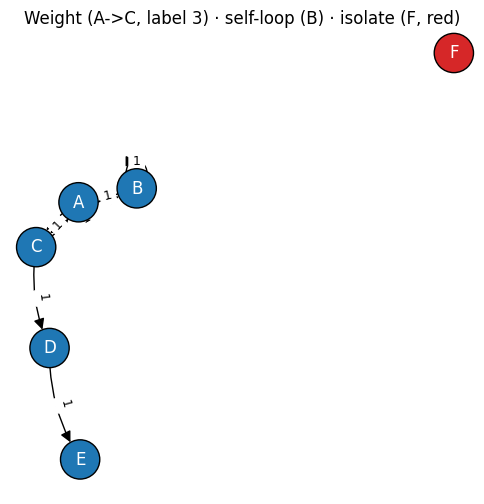

In [10]:
labels2 = ["A", "B", "C", "D", "E", "F"]
M2 = np.array([
    [0, 1, 3, 0, 0, 0],   # A -> B (1), A -> C (weight 3)
    [0, 1, 1, 0, 0, 0],   # B -> B (self-loop), B -> C
    [1, 0, 0, 1, 0, 0],   # C -> A, C -> D
    [0, 0, 0, 0, 1, 0],   # D -> E
    [0, 0, 0, 0, 0, 0],   # E (no outgoing)
    [0, 0, 0, 0, 0, 0],   # F: all zero row AND column -> isolate
])
print("Matrix with a planted weight, isolate, and self-loop:")
print(M2)

G2 = nx.from_numpy_array(M2, create_using=nx.DiGraph)
G2 = nx.relabel_nodes(G2, dict(enumerate(labels2)))

isolates = list(nx.isolates(G2))
self_loops = list(nx.selfloop_edges(G2, data=True))
weighted_edges = [(u, v, d["weight"]) for u, v, d in G2.edges(data=True) if d["weight"] != 1]

print("\nChecks:")
print(f"  Isolate(s) found      : {isolates}  (expected: ['F'])")
print(f"  Self-loop(s) found    : {self_loops}  (expected: [('B', 'B', {{'weight': 1}})])")
print(f"  Edge(s) with weight != 1 : {weighted_edges}  (expected: [('A', 'C', 3)])")

assert isolates == ["F"]
assert len(self_loops) == 1 and self_loops[0][0] == "B" and self_loops[0][1] == "B"
assert weighted_edges == [("A", "C", 3)]
print("\nAll three planted features (weight, isolate, self-loop) show up exactly where expected.")

fig, ax = plt.subplots(figsize=(6, 6))
pos = nx.spring_layout(G2, seed=2)
edge_labels = {(u, v): d["weight"] for u, v, d in G2.edges(data=True)}
node_colors = ["tab:red" if n in isolates else "tab:blue" for n in G2.nodes()]
nx.draw(G2, pos, ax=ax, with_labels=True, node_color=node_colors, font_color="white",
        connectionstyle="arc3,rad=0.15", arrowsize=16, node_size=800,
        edgecolors="black", linewidths=1)
nx.draw_networkx_edge_labels(G2, pos, edge_labels=edge_labels, ax=ax, font_size=9)
ax.set_title("Weight (A->C, label 3) · self-loop (B) · isolate (F, red)")
plt.show()


## Wrap-up

- Part 2: Karate Club loaded, drawn, `n`/`m`/top-5 reported.
- Part 3: scaffolding is here — **the by-hand count and the 3-sentence reflection are still yours to fill in above.**
- Part 4: a hand-written adjacency matrix reproduces the site's explorable exactly — directed graph, row/col sums matching `in_degree`/`out_degree`, symmetrization removing arrowheads, and a planted weight/isolate/self-loop all showing up exactly where expected.
